# Prepración del entorno
Procedemos a realizar las importaciones necesarias así como la carga de datos del archivo. 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv('/workspace/dataset.csv')

# Exploración y limpieza de los datos
Vamos a realizar un análisis exploratorio inicial para identificar valores faltantes y si los hubiera, imputarlos. 

In [2]:
print("Información inicial del dataset:")
df.info()

Información inicial del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460

Como vemos hay columnas con valores faltantes, para la imputación lo vamos a dividir en columnas categóricas y numéricas. Además, procedemos a codificar las variables categóricas. 

In [3]:
columnas_numericas = df.select_dtypes(include=['number']).columns
columnas_categoricas = df.select_dtypes(include=['object']).columns

for col in columnas_numericas:
    df[col] = df[col].fillna(df[col].median())

for col in columnas_categoricas:
    df[col] = df[col].fillna(df[col].mode()[0])

df_limpio = pd.get_dummies(df, columns=columnas_categoricas)

print(f"\nDimensiones del dataset tras limpieza y codificación: {df_limpio.shape}")


Dimensiones del dataset tras limpieza y codificación: (1460, 289)


# Normalización de los datos
Debido a que el PCA es muy sensible a la escala de las variables ya que maximiza la varianza es necesario estandarizar. 

In [4]:
scaler = StandardScaler()

datos_escalados = scaler.fit_transform(df_limpio)

# Aplicación del PCA
Aplicamos el algoritmo de reducción de dimensionalidad especificando el límite de 30 componentes principales.

In [5]:
pca = PCA(n_components=30)

datos_pca = pca.fit_transform(datos_escalados)

# Visualización y análisis de resultados
Generamos un gráfico combinado para entender cuánta información retienen nuestros nuevos componentes.


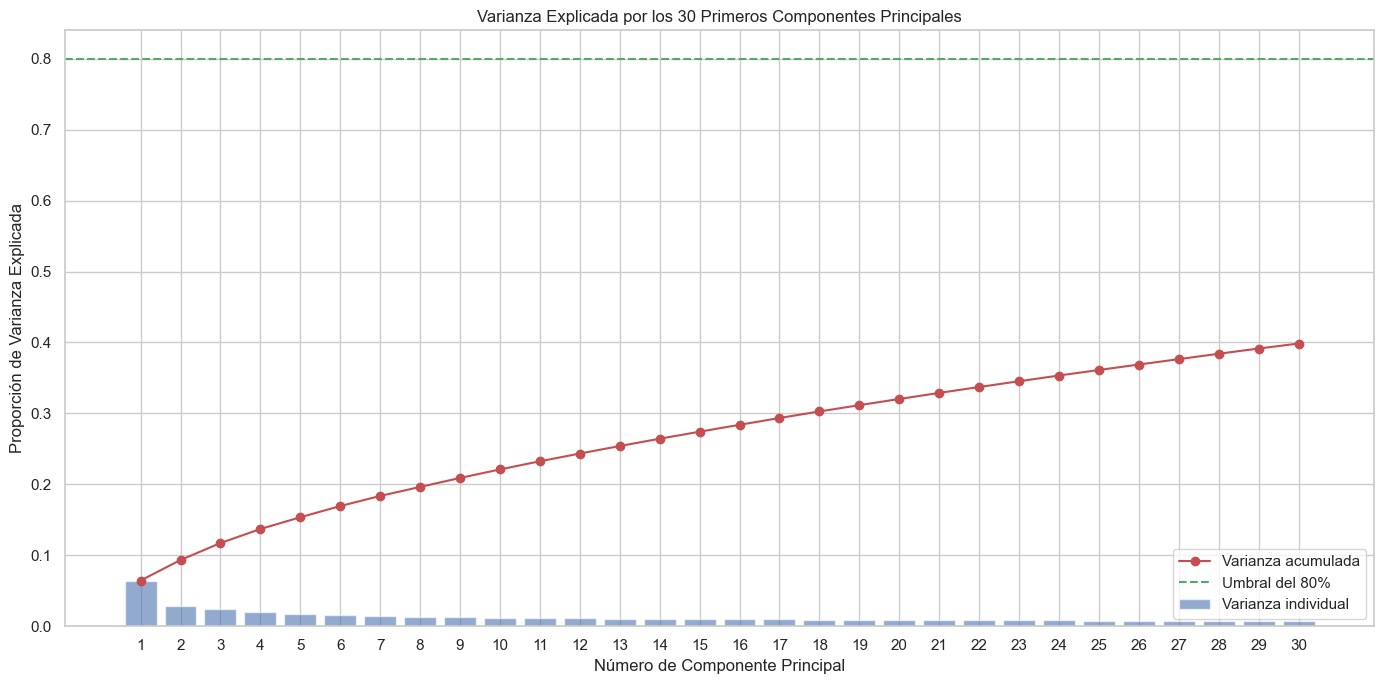

Varianza explicada acumulada por los 30 primeros componentes: 0.3985 (39.85%)


In [6]:
varianza_individual = pca.explained_variance_ratio_
varianza_acumulada = varianza_individual.cumsum()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

plt.bar(range(1, 31), varianza_individual, alpha=0.6, color='b', align='center', 
        label='Varianza individual')

plt.plot(range(1, 31), varianza_acumulada, marker='o', color='r', linestyle='-', 
         label='Varianza acumulada')

plt.xlabel('Número de Componente Principal')
plt.ylabel('Proporción de Varianza Explicada')
plt.title('Varianza Explicada por los 30 Primeros Componentes Principales')
plt.xticks(range(1, 31))
plt.axhline(y=0.8, color='g', linestyle='--', label='Umbral del 80%')
plt.legend(loc='best')
plt.tight_layout()

plt.show()

total_varianza = varianza_acumulada[-1]
print(f"Varianza explicada acumulada por los 30 primeros componentes: {total_varianza:.4f} ({total_varianza * 100:.2f}%)")

#  Evaluación de la varianza explicada

La varianza explicada acumulada es inferior al 80%.

Normalmente se necesitaría aumentar el número de componentes para capturar más información útil, aunque para este proyecto específico mantendremos los 30 componentes solicitados.